In [1]:
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt


In [2]:
X, y = make_circles(n_samples= 1000, 
                    noise= 0.03,
                    random_state= 42)

print(len(X), len(y))

1000 1000


In [3]:
X[:5]

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       [-0.39373073,  0.69288277],
       [ 0.44220765, -0.89672343]])

In [4]:
y[:5]

array([1, 1, 1, 1, 0], dtype=int64)

In [5]:
X.shape, y.shape

((1000, 2), (1000,))

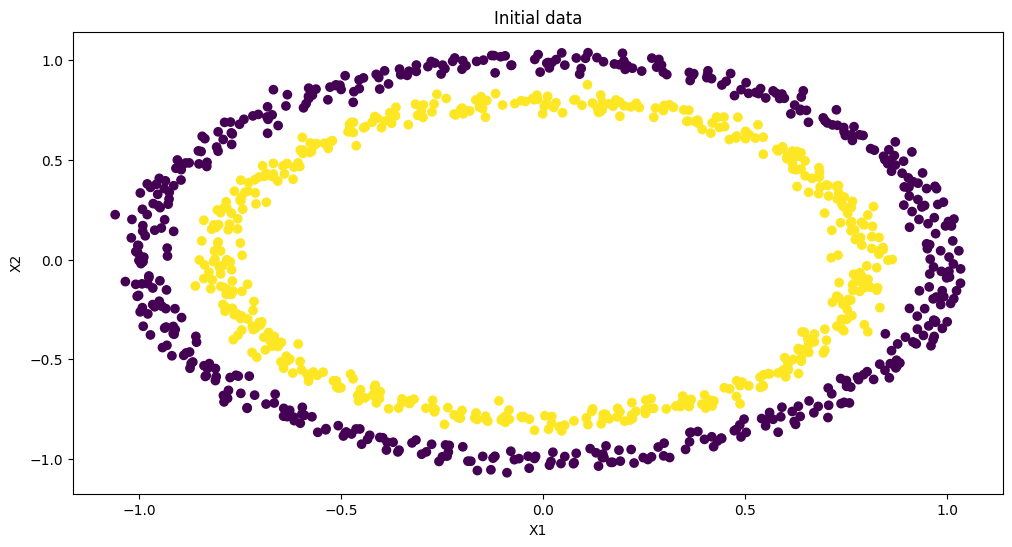

In [6]:
# plot the data
def plot_data():
    plt.figure(figsize=(12,6))
    plt.scatter(X[:,0], X[:,1], c= y.data)
    plt.title('Initial data')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.show()

plot_data()

In [7]:
print(X.shape, y.shape) # --- DIFFERENT SHAPE

print(X.dtype, y.dtype)

(1000, 2) (1000,)
float64 int64


In [8]:
# Convert data to tensors
import torch
from sklearn.model_selection import train_test_split

X =  torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

print(X.dtype, y.dtype)

torch.float32 torch.float32


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

print(len(X_train), len(y_train))
print(len(X_test), len(y_test))

800 800
200 200


In [10]:
# Building a model

from torch import nn
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [11]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()
        
        
        
    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))
    
    

In [12]:
model = CircleModel().to(device)
model

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [13]:
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(params= model.parameters(), lr= 0.1)

In [14]:
# Calculate accuracy (a classification metric)

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item() # torch.eq() calculates where two tensors are equal
    acc = (correct / len(y_pred)) * 100 
    return acc

In [15]:
# train and test loops

torch.manual_seed(42)

epochs = 1000
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

epochs_count = []
train_losses = []
test_losses = []

train_acc = []
test_acc = []


for epoch in range(epochs):
    # Train
    model.train()
    y_logits = model(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))
    loss = loss_fn(y_logits, y_train)  # Using nn.BCEWithLogitsLoss works with raw logits
     # loss = loss_fn(torch.sigmoid(y_logits), # Using nn.BCELoss we need torch.sigmoid()!!!!!
    acc_train = accuracy_fn(y_train, y_pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Test
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        
        test_loss = loss_fn(test_logits,y_test)
        acc_test = accuracy_fn(y_test, test_pred)
        
        
    if epoch % 10 == 0:
        epochs_count.append(epoch)
        train_losses.append(loss)
        test_losses.append(test_loss)
        train_acc.append(acc_train)
        test_acc.append(acc_test)
        print(f"Epoch : {epoch} | Train accuracy : {acc_train:.2f}% | Test accuracy : {acc_test:.2f}% | Train loss: {loss:.5f} | Test Loss : {test_loss:.5f}")

Epoch : 0 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.70922 | Test Loss : 0.70872
Epoch : 10 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.70119 | Test Loss : 0.70126
Epoch : 20 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.69728 | Test Loss : 0.69761
Epoch : 30 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.69500 | Test Loss : 0.69547
Epoch : 40 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.69362 | Test Loss : 0.69421
Epoch : 50 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.69279 | Test Loss : 0.69345
Epoch : 60 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.69224 | Test Loss : 0.69295
Epoch : 70 | Train accuracy : 50.00% | Test accuracy : 50.00% | Train loss: 0.69183 | Test Loss : 0.69259
Epoch : 80 | Train accuracy : 50.88% | Test accuracy : 50.50% | Train loss: 0.69151 | Test Loss : 0.69231
Epoch : 90 | Train accuracy : 55.88% | Test acc

In [16]:
# Make predictions
model.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model(X_test))).squeeze()
y_preds[:10], y[:10] 

(tensor([1., 1., 1., 0., 1., 1., 0., 0., 1., 0.]),
 tensor([1., 1., 1., 1., 0., 1., 1., 1., 1., 0.]))

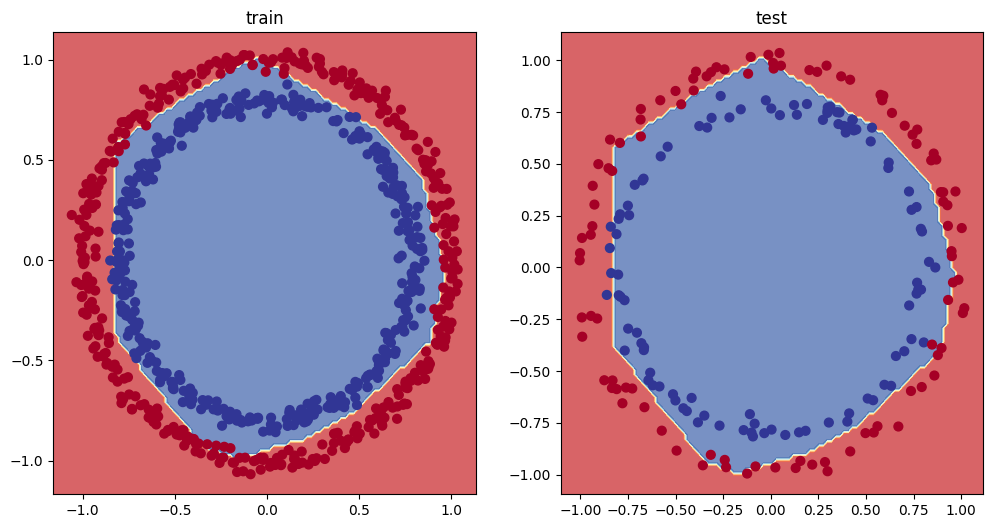

In [17]:
from plot_decision_boundries import plot_decision_boundary, plot_predictions

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('train')
plot_decision_boundary(model, X_train, y_train)

plt.subplot(1,2,2)
plt.title('test')
plot_decision_boundary(model, X_test, y_test)


## Another example using make_blobs

In [75]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import torch
from torch import nn

In [76]:
# create and plot data

X, y = make_blobs(n_samples= 1000,
                  n_features= 2,
                  centers= 4,
                  cluster_std= 1.5,
                  random_state= 42)




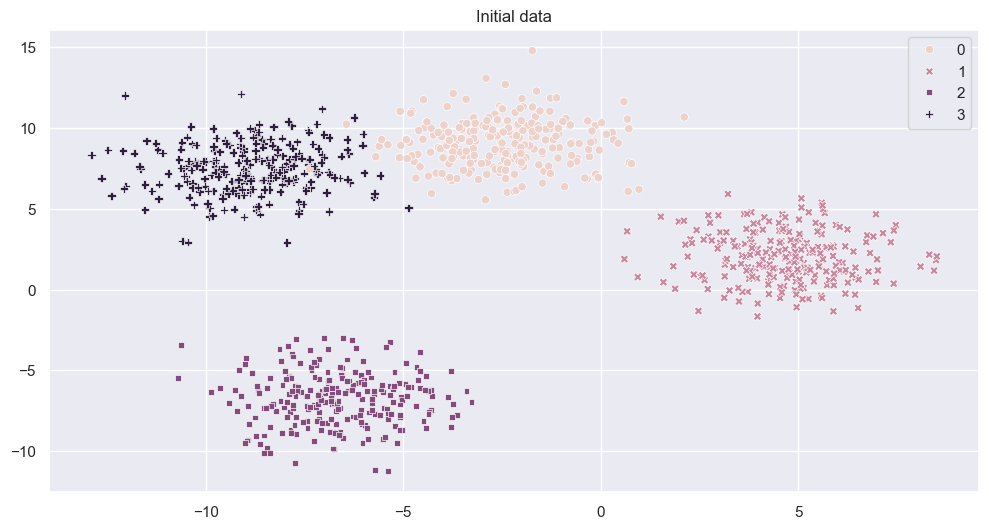

In [77]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x=X[:,0], y=X[:,1], hue= y, style= y )
plt.title('Initial data')
plt.legend()
plt.show()

In [78]:
print(X[:2], y[:2])

[[-8.41339595  6.93516545]
 [-5.76648413 -6.43117072]] [3 2]


In [79]:
print(type(X), type(y))
print(X.shape, y.shape)

<class 'numpy.ndarray'> <class 'numpy.ndarray'>
(1000, 2) (1000,)


In [80]:
# convert data to tensor
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.LongTensor)

In [81]:
print(type(X), type(y))
print(X.shape, y.shape)

<class 'torch.Tensor'> <class 'torch.Tensor'>
torch.Size([1000, 2]) torch.Size([1000])


In [82]:
# split data into train and test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size= 0.2,
                                                    random_state= 42)

print(len(X_train), len(y_train), len(X_test), len(y_test))

800 800 200 200


In [83]:
# Building the model

class ClassificationBloob(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.layer1 = nn.Linear(in_features= 2, out_features= 10)
        self.layer2 = nn.Linear(in_features= 10, out_features= 10)
        self.layer3 = nn.Linear(in_features= 10, out_features= 4)
        self.relu = nn.ReLU()
        
        
        
    def forward(self, x):
        return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))
    
    
            

In [84]:
model = ClassificationBloob()
model

ClassificationBloob(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=4, bias=True)
  (relu): ReLU()
)

In [85]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params= model.parameters(), lr= 0.1)

In [87]:
torch.manual_seed(42)
epochs = 100

for epoch in range(epochs):
    # #### Train ####
    
    model.train()
    y_logits = model(X_train)
    y_pred = torch.softmax(y_logits, dim= 1).argmax(dim= 1)
    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_train, y_pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    
    # #### Test ####
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test)
        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
        
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_test, test_pred)
        
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 1.40627, Acc: 1.62% | Test Loss: 1.37291, Test Acc: 1.00%
Epoch: 10 | Loss: 0.99293, Acc: 51.38% | Test Loss: 0.98699, Test Acc: 64.00%
Epoch: 20 | Loss: 0.50941, Acc: 91.00% | Test Loss: 0.51096, Test Acc: 90.00%
Epoch: 30 | Loss: 0.34822, Acc: 97.88% | Test Loss: 0.35120, Test Acc: 98.50%
Epoch: 40 | Loss: 0.20682, Acc: 99.00% | Test Loss: 0.19750, Test Acc: 99.50%
Epoch: 50 | Loss: 0.10386, Acc: 99.00% | Test Loss: 0.09480, Test Acc: 99.50%
Epoch: 60 | Loss: 0.06691, Acc: 99.00% | Test Loss: 0.05865, Test Acc: 99.50%
Epoch: 70 | Loss: 0.05237, Acc: 99.00% | Test Loss: 0.04409, Test Acc: 99.50%
Epoch: 80 | Loss: 0.04504, Acc: 99.00% | Test Loss: 0.03659, Test Acc: 99.50%
Epoch: 90 | Loss: 0.04067, Acc: 99.00% | Test Loss: 0.03205, Test Acc: 99.50%


In [91]:
# Make predictions
model.eval()
with torch.inference_mode():
    y_logits = model(X_test)
    y_pred_probs = torch.softmax(y_logits, dim=1)
    y_preds = y_logits.argmax(dim= 1)


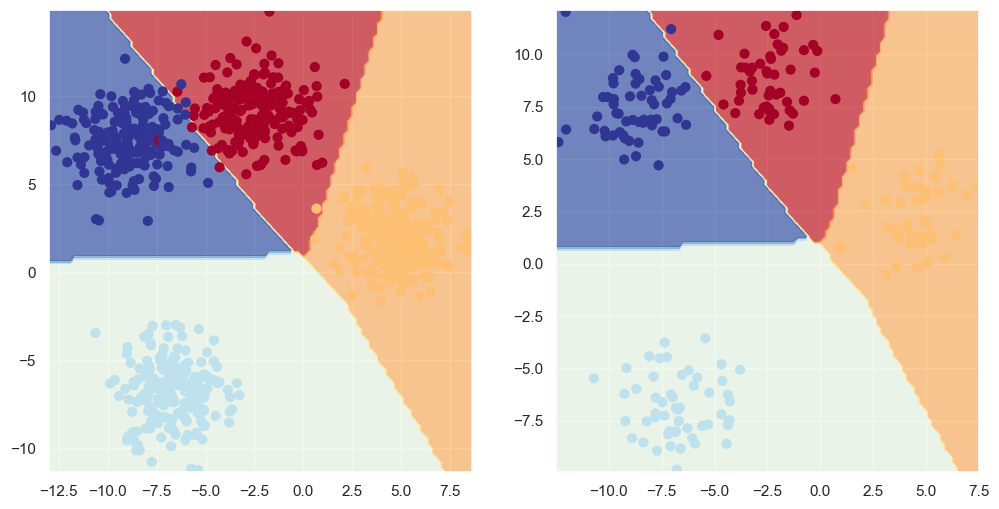

In [92]:
plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
plot_decision_boundary(model, X_train, y_train)

plt.subplot(1, 2, 2)
plot_decision_boundary(model, X_test, y_test)

In [93]:
from sklearn.metrics import accuracy_score

accuracy_score(y_preds, y_test)

0.995